# 📊 Khám phá và Phân tích Dữ liệu (EDA) - Twitter Customer Support (TWCS)

**Môn học / Dự án:** TMG301 - Text Mining & NLP  
**Tập dữ liệu:** `twcs.csv` (~2.8 triệu dòng, 516 MB) & `sample.csv`  
**Nguồn gốc:** Customer Support on Twitter Dataset (Bộ dữ liệu kinh điển ghi nhận các tương tác hội thoại thực tế giữa khách hàng và các thương hiệu hàng đầu thế giới).  

---

### 🎯 Mục tiêu thực hiện trong Notebook:
1. **Tổng quan & Kích thước dữ liệu (Dataset Overview & Size):** Khảo sát cấu trúc bảng, dung lượng bộ nhớ RAM, kiểm tra missing values và các dòng trùng lặp.
2. **Chiều hướng Hội thoại (Inbound vs Outbound):** So sánh tỷ lệ tin nhắn từ người dùng yêu cầu trợ giúp (`inbound=True`) và phản hồi từ đội ngũ CSKH của thương hiệu (`inbound=False`).
3. **Hệ sinh thái Thương hiệu Hỗ trợ (Brand Ecosystem):** Khảo sát các thương hiệu tích cực nhất (AppleSupport, AmazonHelp, Uber_Support, Delta, SpotifyCares,...).
4. **Cấu trúc Luồng Hội thoại (Conversational Threads):** Phân tích liên kết giữa `tweet_id`, `in_response_to_tweet_id`, và `response_tweet_id`.
5. **Thời gian Phản hồi (Response Latency Analysis):** Đo lường độ trễ từ khi khách hàng hỏi đến khi thương hiệu trả lời (theo phút/giờ).
6. **Đặc trưng Độ dài Văn bản (Text Length Analysis):** Phân tích số ký tự, số từ của tin nhắn Khách hàng vs Thương hiệu; khuyến nghị tham số `max_length` cho các mô hình Transformer / LLM.
7. **Thực thể Mạng Xã Hội (Social Media Entities):** Đo lường tỷ lệ xuất hiện của `@mentions`, đường dẫn URL (`t.co`), `#hashtags` và emoji.
8. **Vốn Từ vựng & N-grams:** Khám phá Top từ khóa và cụm 2 từ (Bigrams) nổi bật trong ngôn ngữ phàn nàn của khách hàng và lời thoại mẫu của hãng.
9. **Xu hướng Thời gian (Temporal Patterns):** Phân tích khung giờ cao điểm và ngày trong tuần có lưu lượng hỗ trợ lớn nhất.
10. **Tổng kết & Khuyến nghị Kỹ thuật (Technical Summary & NLP Recommendations):** Chiến lược tiền xử lý văn bản mạng xã hội (Social Media Text Cleaning) và định hướng bài toán NLP (Sentiment / Intent / Chatbot Response).


## 1. Thiết lập Thư viện & Cấu hình Hiển thị


In [1]:
import os
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện biểu đồ chuyên nghiệp
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# Cấu hình Pandas hiển thị đầy đủ
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

print("✅ Đã tải xong các thư viện cần thiết!")


✅ Đã tải xong các thư viện cần thiết!


## 2. Tải Dữ liệu Twitter Customer Support

Đường dẫn được cấu hình linh hoạt để tự động nhận diện file `twcs.csv` từ thư mục gốc dự án hoặc thư mục `EDA/`. Nếu đang trong quá trình phát triển nhanh, bạn có thể chuyển cờ `USE_SAMPLE = True` để dùng `sample.csv`.


In [2]:
candidate_paths = [
    Path("datasets/twitter/twcs/twcs.csv"),
    Path("../datasets/twitter/twcs/twcs.csv"),
    Path.cwd() / "datasets" / "twitter" / "twcs" / "twcs.csv",
    Path.cwd().parent / "datasets" / "twitter" / "twcs" / "twcs.csv",
    Path("datasets/twitter/sample.csv"),
    Path("../datasets/twitter/sample.csv"),
]

file_path = None
for p in candidate_paths:
    if p.exists():
        file_path = p
        break

if file_path is None:
    raise FileNotFoundError("❌ Không tìm thấy file dữ liệu Twitter trong thư mục datasets/twitter/!")

print(f"📂 Đang đọc dữ liệu từ: {file_path.resolve()}")
file_size_mb = file_path.stat().st_size / (1024 * 1024)
print(f"📦 Dung lượng file đĩa: {file_size_mb:.2f} MB")

# Cấu hình số dòng đọc để tối ưu tài nguyên RAM:
# Đọc 300,000 dòng để phân tích đại diện nhanh và toàn diện (hoặc đặt nrows=None để đọc toàn bộ ~2.8M dòng nếu máy có RAM >= 16GB)
LOAD_ROWS = 300000 if file_size_mb > 50 else None

if LOAD_ROWS:
    print(f"⚡ Đọc {LOAD_ROWS:,} dòng đầu tiên để phân tích chuyên sâu...")
    df = pd.read_csv(file_path, nrows=LOAD_ROWS, encoding="utf-8")
else:
    df = pd.read_csv(file_path, encoding="utf-8")

print(f"✅ Đã tải thành công {len(df):,} dòng dữ liệu!")


📂 Đang đọc dữ liệu từ: D:\FPTU\26FALL\TMG301\project\datasets\twitter\twcs\twcs.csv
📦 Dung lượng file đĩa: 492.58 MB
⚡ Đọc 300,000 dòng đầu tiên để phân tích chuyên sâu...
✅ Đã tải thành công 300,000 dòng dữ liệu!


## 3. Kích thước & Cấu trúc Tổng quan (Dataset Dimensions & Overview)

Kiểm tra kích thước (số dòng, số cột), kiểu dữ liệu và bộ nhớ RAM chiếm dụng.


In [3]:
num_rows, num_cols = df.shape
mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)

summary_dim_df = pd.DataFrame({
    "Chỉ số": ["Tổng số dòng (Mẫu tweet)", "Tổng số thuộc tính (Cột)", "Dung lượng RAM chiếm dụng", "Danh sách các cột"],
    "Giá trị": [
        f"{num_rows:,} mẫu",
        f"{num_cols} cột",
        f"{mem_mb:.2f} MB",
        ", ".join(df.columns.tolist())
    ]
})

print("=== BẢNG TỔNG QUAN KÍCH THƯỚC DỮ LIỆU ===")
display(summary_dim_df)

print("\n--- Thông tin kiểu dữ liệu và bộ nhớ (df.info()) ---")
df.info()


=== BẢNG TỔNG QUAN KÍCH THƯỚC DỮ LIỆU ===


,Chỉ số,Giá trị
0,Tổng số dòng (Mẫu tweet),"300,000 mẫu"
1,Tổng số thuộc tính (Cột),7 cột
2,Dung lượng RAM chiếm dụng,122.80 MB
3,Danh sách các cột,"tweet_id, author_id, inbound, created_at, text, response_tweet_id, in_response_to_tweet_id"



--- Thông tin kiểu dữ liệu và bộ nhớ (df.info()) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 7 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   tweet_id                 300000 non-null  int64  
 1   author_id                300000 non-null  object 
 2   inbound                  300000 non-null  bool   
 3   created_at               300000 non-null  object 
 4   text                     300000 non-null  object 
 5   response_tweet_id        200630 non-null  object 
 6   in_response_to_tweet_id  223082 non-null  float64
dtypes: bool(1), float64(1), int64(1), object(4)
memory usage: 14.0+ MB


### Xem trước các dòng mẫu đầu tiên và ngẫu nhiên


In [4]:
print("--- 3 Dòng đầu tiên của tập dữ liệu ---")
display(df.head(3))

print("\n--- 3 Dòng lấy mẫu ngẫu nhiên (Random Sample) ---")
display(df.sample(3, random_state=42))


--- 3 Dòng đầu tiên của tập dữ liệu ---


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist you. We would need to get you into a private secured link to further assist.,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messages and no one is responding as usual,1,4.0



--- 3 Dòng lấy mẫu ngẫu nhiên (Random Sample) ---


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
4941,7569,ChipotleTweets,False,Tue Oct 31 23:39:53 +0000 2017,@117267 😍 Adorable! -Becky,NaN,7570.0
51775,63789,GWRHelp,False,Thu Nov 30 07:44:25 +0000 2017,@130662 Hi Russell. What journey are you making please? Natalie,NaN,63790.0
115253,142873,AmazonHelp,False,Fri Nov 24 19:20:29 +0000 2017,@148250 Thank you for the information. Some items can take longer to process. You can find more information here: https://t.co/G8voAavjiV. ^AL,142874,142872.0


## 4. Kiểm tra Giá trị Thiếu (Missing Values) & Tính Toàn Vẹn Chuỗi Hội Thoại

Trong bài toán Twitter Customer Support:
- `response_tweet_id` và `in_response_to_tweet_id` có giá trị thiếu (NaN) là hoàn toàn bình thường vì:
  - Nếu một tweet là mở đầu cuộc hội thoại (root tweet), nó sẽ không có `in_response_to_tweet_id`.
  - Nếu một tweet là câu kết thúc hoặc chưa được trả lời, nó sẽ không có `response_tweet_id`.


In [5]:
missing_df = pd.DataFrame({
    "Số lượng Missing": df.isnull().sum(),
    "Tỷ lệ (%)": (df.isnull().sum() / len(df) * 100).round(2)
})
missing_df["Ý nghĩa nghiệp vụ"] = [
    "Khóa chính (Unique ID), không được phép thiếu",
    "Tên hoặc mã định danh của người gửi tweet",
    "Cờ đánh dấu hướng tin nhắn (True/False)",
    "Thời điểm đăng tweet",
    "Nội dung văn bản tweet",
    "ID của tweet phản hồi (NaN nếu là tweet cuối/chưa trả lời)",
    "ID của tweet nguồn (NaN nếu là tweet mở đầu hội thoại)"
]

display(missing_df)

print(f"Số dòng trùng lặp hoàn toàn: {df.duplicated().sum()}")
print(f"Số tweet có nội dung trùng lặp: {df.duplicated(subset=['text']).sum():,}")


,Số lượng Missing,Tỷ lệ (%),Ý nghĩa nghiệp vụ
tweet_id,0,0.00,"Khóa chính (Unique ID), không được phép thiếu"
author_id,0,0.00,Tên hoặc mã định danh của người gửi tweet
inbound,0,0.00,Cờ đánh dấu hướng tin nhắn (True/False)
created_at,0,0.00,Thời điểm đăng tweet
text,0,0.00,Nội dung văn bản tweet
response_tweet_id,99370,33.12,ID của tweet phản hồi (NaN nếu là tweet cuối/chưa trả lời)
in_response_to_tweet_id,76918,25.64,ID của tweet nguồn (NaN nếu là tweet mở đầu hội thoại)


Số dòng trùng lặp hoàn toàn: 0
Số tweet có nội dung trùng lặp: 1,915


## 5. Phân tích Chiều hướng Tin nhắn: Inbound vs Outbound

- `inbound = True`: Khách hàng gửi yêu cầu / thắc mắc / phàn nàn đến thương hiệu.
- `inbound = False`: Đội ngũ hỗ trợ (Customer Support Agents / Bots) của các thương hiệu trả lời khách hàng.


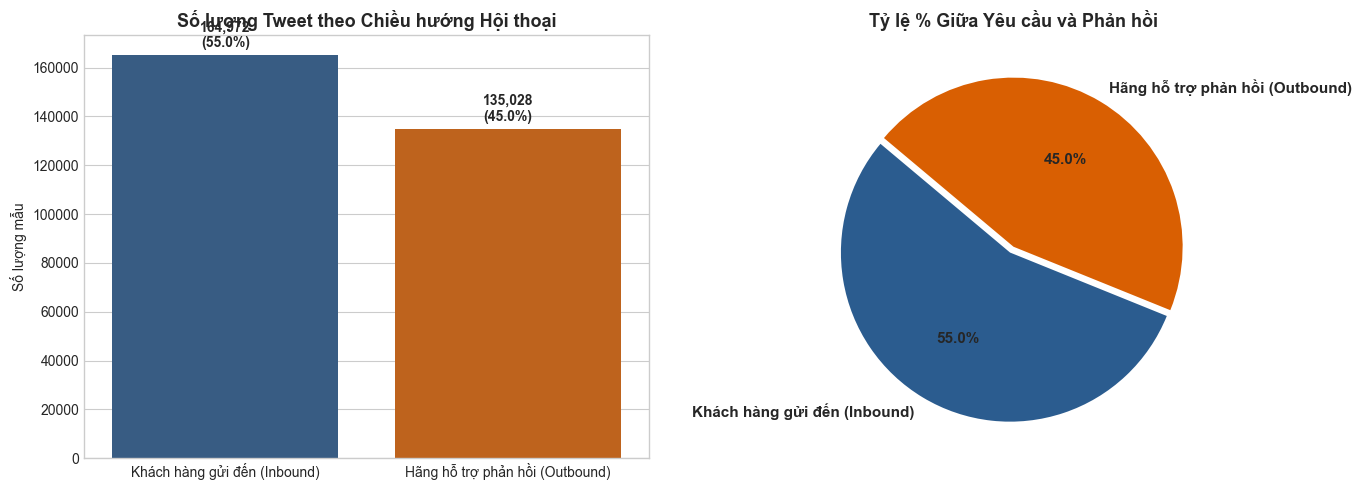

In [6]:
inbound_counts = df["inbound"].value_counts()
labels = ["Khách hàng gửi đến (Inbound)", "Hãng hỗ trợ phản hồi (Outbound)"]
counts = [inbound_counts.get(True, 0), inbound_counts.get(False, 0)]
colors = ["#2b5c8f", "#d95f02"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ cột
sns.barplot(x=labels, y=counts, palette=colors, ax=axes[0], hue=labels, legend=False)
axes[0].set_title("Số lượng Tweet theo Chiều hướng Hội thoại", weight="bold")
axes[0].set_ylabel("Số lượng mẫu")
for i, v in enumerate(counts):
    axes[0].text(i, v + (max(counts) * 0.02), f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", weight="bold")

# Biểu đồ tròn
axes[1].pie(
    counts,
    labels=labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    explode=(0.04, 0),
    textprops={"fontsize": 11, "weight": "bold"}
)
axes[1].set_title("Tỷ lệ % Giữa Yêu cầu và Phản hồi", weight="bold")
plt.tight_layout()
plt.show()


## 6. Khảo sát Top Thương hiệu Chăm sóc Khách hàng Tích cực nhất

Lọc các tweet có `inbound = False` (do hãng đăng tải) để xác định các nhãn hàng nào có lưu lượng hỗ trợ khách hàng lớn nhất trên Twitter.


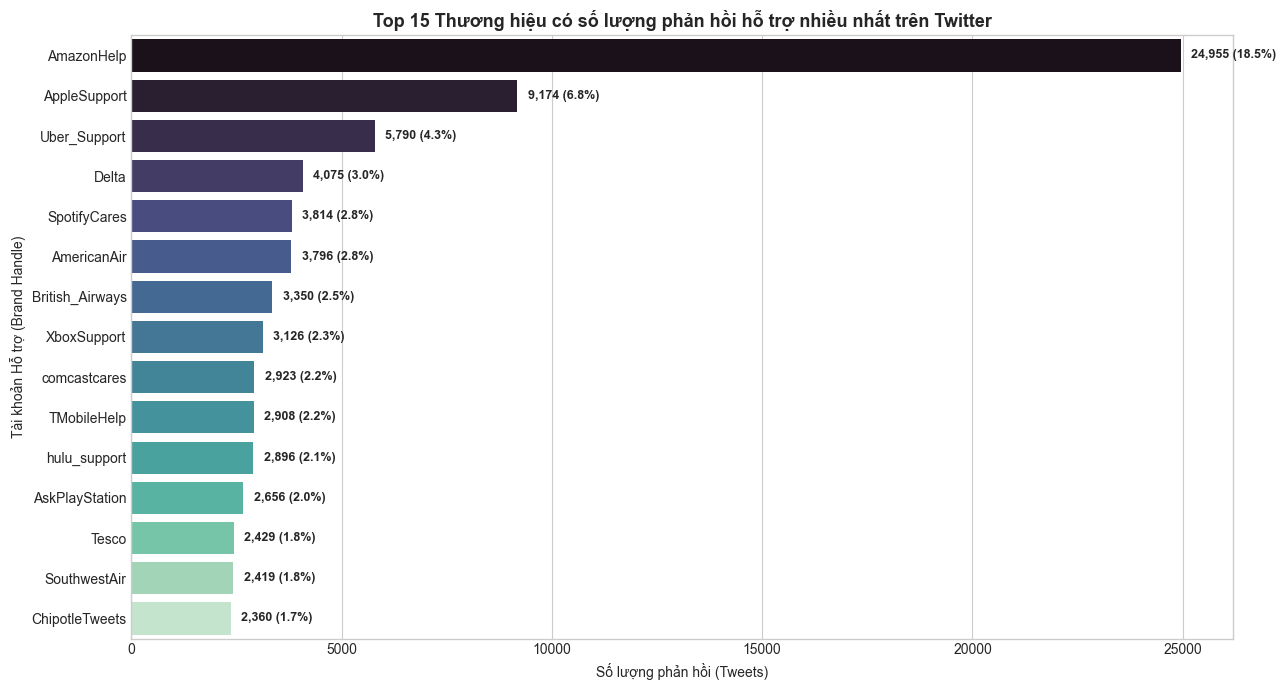

In [7]:
brand_df = df[df["inbound"] == False]
top_brands = brand_df["author_id"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(13, 7))
palette = sns.color_palette("mako", len(top_brands))
sns.barplot(x=top_brands.values, y=top_brands.index, palette=palette, ax=ax, hue=top_brands.index, legend=False)
ax.set_title("Top 15 Thương hiệu có số lượng phản hồi hỗ trợ nhiều nhất trên Twitter", fontsize=13, weight="bold")
ax.set_xlabel("Số lượng phản hồi (Tweets)")
ax.set_ylabel("Tài khoản Hỗ trợ (Brand Handle)")

for i, v in enumerate(top_brands.values):
    pct = v / len(brand_df) * 100
    ax.text(v + (max(top_brands.values) * 0.01), i, f"{v:,} ({pct:.1f}%)", va="center", fontsize=9, weight="bold")

plt.tight_layout()
plt.show()


## 7. Phân tích Thời gian Phản hồi (Response Latency)

Một chỉ số cực kỳ quan trọng trong CRM và AI Chăm sóc khách hàng là **Thời gian phản hồi (First Response Time / Latency)**:  
Khách hàng phải chờ bao lâu kể từ khi tweet phàn nàn cho đến khi nhận được phản hồi đầu tiên từ nhân viên hỗ trợ?


C:\Users\Admin\AppData\Local\Temp\ipykernel_51488\1978344062.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_time["created_at_dt"] = pd.to_datetime(df_time["created_at"], errors="coerce")


--- THỐNG KÊ THỜI GIAN PHẢN HỒI (PHÚT) ---
Số lượng cặp hỏi - đáp khớp được: 126,840
Thời gian phản hồi trung vị (Median): 18.0 phút
Thời gian phản hồi trung bình (Mean):  101.2 phút
Phân vị 75% (75th percentile):       70.6 phút


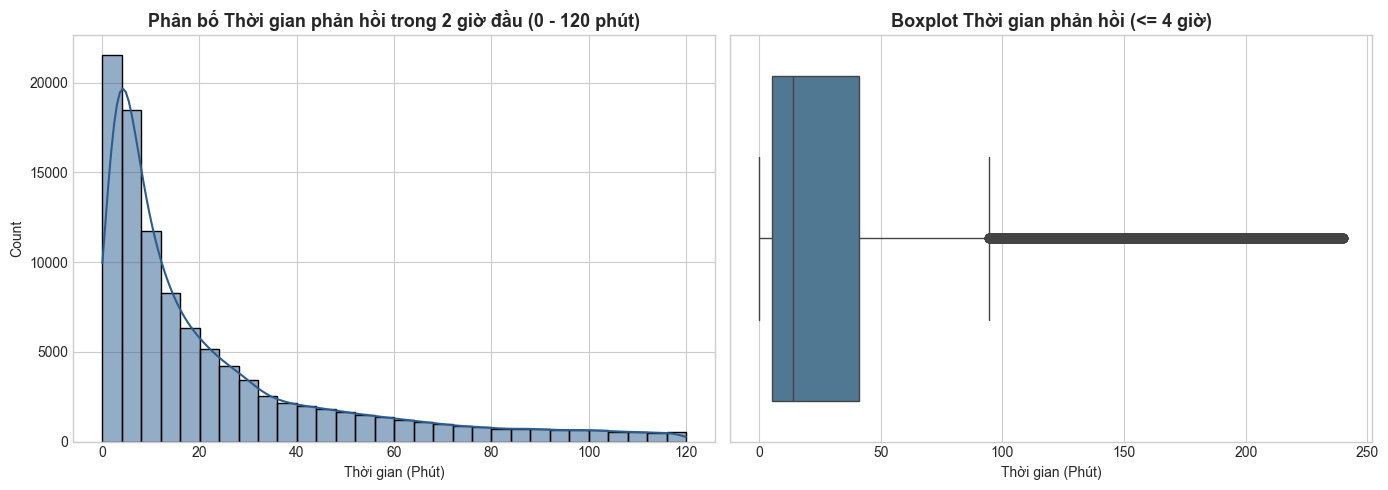

In [8]:
# Chuyển đổi timestamp
df_time = df[["tweet_id", "inbound", "created_at", "in_response_to_tweet_id"]].copy()
df_time["created_at_dt"] = pd.to_datetime(df_time["created_at"], errors="coerce")

# Lấy các tweet của thương hiệu trả lời trực tiếp cho tweet của khách hàng
brand_replies = df_time[df_time["inbound"] == False].dropna(subset=["in_response_to_tweet_id"])
cust_tweets = df_time[df_time["inbound"] == True].set_index("tweet_id")["created_at_dt"]

# Ghép nối để tính chênh lệch thời gian
brand_replies = brand_replies[brand_replies["in_response_to_tweet_id"].isin(cust_tweets.index)].copy()
brand_replies["parent_created_at"] = brand_replies["in_response_to_tweet_id"].map(cust_tweets)

brand_replies["response_time_minutes"] = (
    (brand_replies["created_at_dt"] - brand_replies["parent_created_at"]).dt.total_seconds() / 60.0
)

# Lọc các giá trị hợp lệ (> 0 và < 24 giờ để trực quan hóa)
valid_resp_times = brand_replies[
    (brand_replies["response_time_minutes"] >= 0) & (brand_replies["response_time_minutes"] <= 1440)
]["response_time_minutes"]

if len(valid_resp_times) > 0:
    print(f"--- THỐNG KÊ THỜI GIAN PHẢN HỒI (PHÚT) ---")
    print(f"Số lượng cặp hỏi - đáp khớp được: {len(valid_resp_times):,}")
    print(f"Thời gian phản hồi trung vị (Median): {valid_resp_times.median():.1f} phút")
    print(f"Thời gian phản hồi trung bình (Mean):  {valid_resp_times.mean():.1f} phút")
    print(f"Phân vị 75% (75th percentile):       {valid_resp_times.quantile(0.75):.1f} phút")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    # Xem xét phản hồi nhanh trong 120 phút đầu
    sns.histplot(valid_resp_times[valid_resp_times <= 120], bins=30, kde=True, ax=axes[0], color="#2b5c8f")
    axes[0].set_title("Phân bố Thời gian phản hồi trong 2 giờ đầu (0 - 120 phút)", weight="bold")
    axes[0].set_xlabel("Thời gian (Phút)")

    # Boxplot
    sns.boxplot(x=valid_resp_times[valid_resp_times <= 240], ax=axes[1], color="#457b9d")
    axes[1].set_title("Boxplot Thời gian phản hồi (<= 4 giờ)", weight="bold")
    axes[1].set_xlabel("Thời gian (Phút)")

    plt.tight_layout()
    plt.show()
else:
    print("Dữ liệu mẫu chưa đủ cặp tweet cha - con để tính toán latency.")


## 8. Phân tích Đặc trưng Độ dài Văn bản (Text Length Analysis)

Khảo sát số lượng ký tự và số lượng từ trong mỗi tweet để:
- Đánh giá sự khác biệt giữa câu hỏi phàn nàn của khách hàng và câu trả lời mẫu của thương hiệu.
- Xác định ngưỡng `max_length` tối ưu khi đưa vào Tokenizer của BERT, RoBERTa hoặc GPT.


,Chỉ số,Khách hàng (Inbound),Thương hiệu (Outbound)
0,Trung bình (Mean),18.6 từ,19.8 từ
1,Trung vị (Median),18 từ,19 từ
2,Phân vị 90%,30 từ,29 từ
3,Phân vị 95%,39 từ,37 từ
4,Giá trị lớn nhất (Max),90 từ,63 từ


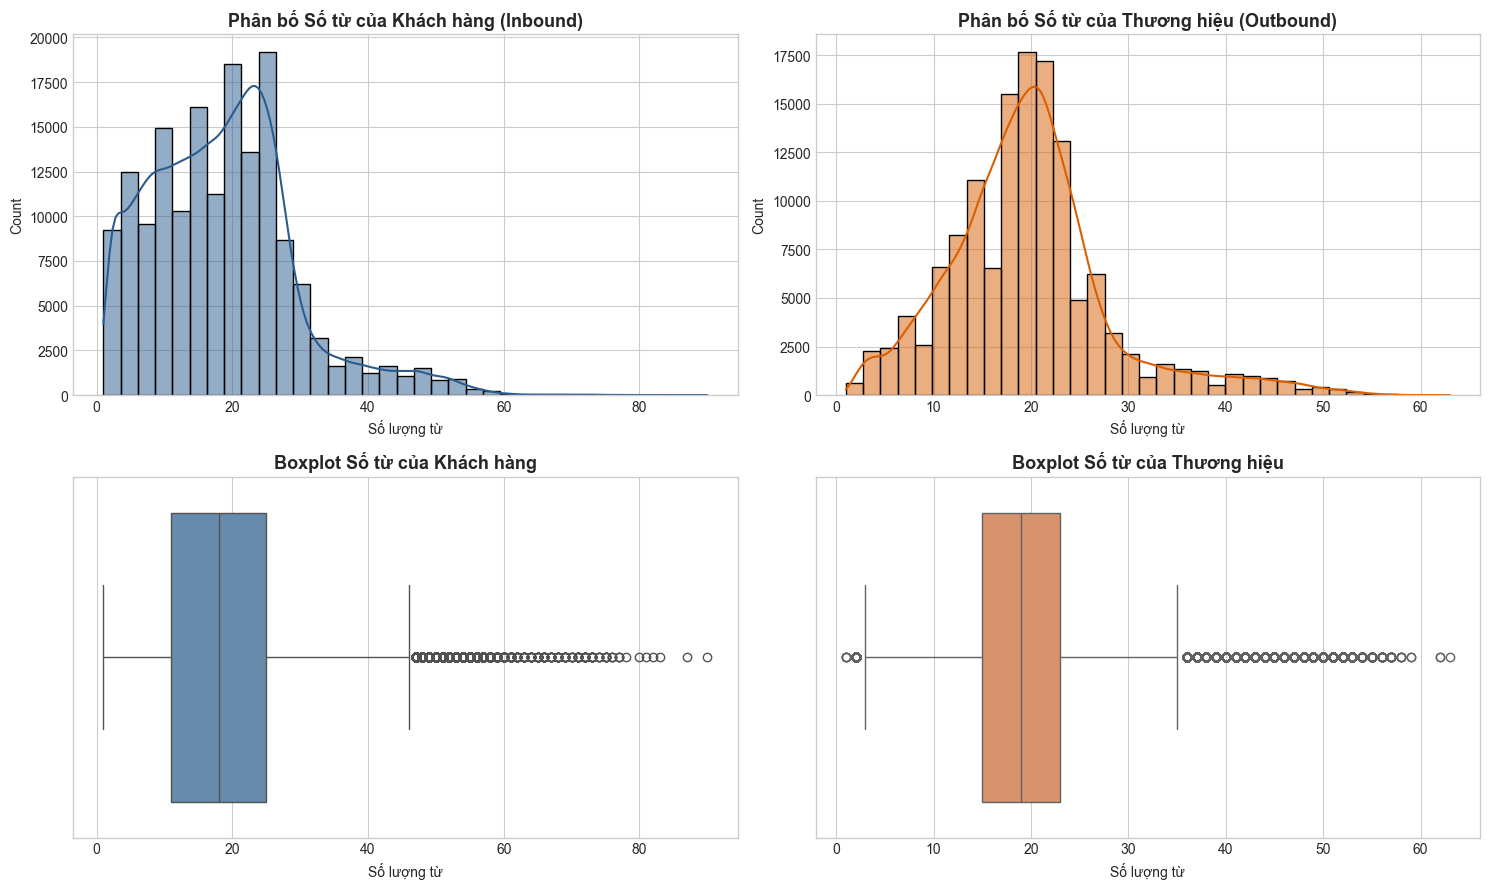

In [9]:
df["char_len"] = df["text"].astype(str).apply(len)
df["word_count"] = df["text"].astype(str).apply(lambda x: len(x.split()))

cust_words = df[df["inbound"] == True]["word_count"]
brand_words = df[df["inbound"] == False]["word_count"]

stats_df = pd.DataFrame({
    "Chỉ số": ["Trung bình (Mean)", "Trung vị (Median)", "Phân vị 90%", "Phân vị 95%", "Giá trị lớn nhất (Max)"],
    "Khách hàng (Inbound)": [
        f"{cust_words.mean():.1f} từ",
        f"{cust_words.median():.0f} từ",
        f"{cust_words.quantile(0.90):.0f} từ",
        f"{cust_words.quantile(0.95):.0f} từ",
        f"{cust_words.max()} từ"
    ],
    "Thương hiệu (Outbound)": [
        f"{brand_words.mean():.1f} từ",
        f"{brand_words.median():.0f} từ",
        f"{brand_words.quantile(0.90):.0f} từ",
        f"{brand_words.quantile(0.95):.0f} từ",
        f"{brand_words.max()} từ"
    ]
})

display(stats_df)

# Trực quan hóa
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sns.histplot(cust_words, bins=35, kde=True, ax=axes[0, 0], color="#2b5c8f")
axes[0, 0].set_title("Phân bố Số từ của Khách hàng (Inbound)", weight="bold")
axes[0, 0].set_xlabel("Số lượng từ")

sns.histplot(brand_words, bins=35, kde=True, ax=axes[0, 1], color="#d95f02")
axes[0, 1].set_title("Phân bố Số từ của Thương hiệu (Outbound)", weight="bold")
axes[0, 1].set_xlabel("Số lượng từ")

sns.boxplot(x=cust_words, ax=axes[1, 0], color="#5b8bb8")
axes[1, 0].set_title("Boxplot Số từ của Khách hàng", weight="bold")
axes[1, 0].set_xlabel("Số lượng từ")

sns.boxplot(x=brand_words, ax=axes[1, 1], color="#e88c5d")
axes[1, 1].set_title("Boxplot Số từ của Thương hiệu", weight="bold")
axes[1, 1].set_xlabel("Số lượng từ")

plt.tight_layout()
plt.show()


## 9. Khảo sát Thực thể Đặc thù Mạng Xã Hội (Social Media Entities)

Dữ liệu Twitter chứa nhiều yếu tố phi chuẩn (Unstructured & Noisy components):
- `@mentions`: Tên người dùng / thương hiệu được nhắc đến.
- Đường dẫn URL (`t.co`, `https://...`): Thường dùng để điều hướng khách hàng về trang hỗ trợ nội bộ hoặc trang bảo mật.
- `#hashtags`: Từ khóa gắn thẻ chủ đề hoặc than phiền.


,Thực thể mạng xã hội,Tỷ lệ (%),Số lượng mẫu chứa,Khuyến nghị tiền xử lý
0,Chứa @mention,97.791000,293373,Thay bằng token đặc biệt `<USER>` / `<BRAND>` hoặc loại bỏ để tránh overfit tên
1,Chứa Link / URL,20.944000,62832,Thay bằng token `<URL>` để chuẩn hóa cấu trúc câu
2,Chứa #hashtag,5.517333,16552,Tách dấu thăng (#) giữ lại từ vựng hoặc gom nhóm chủ đề


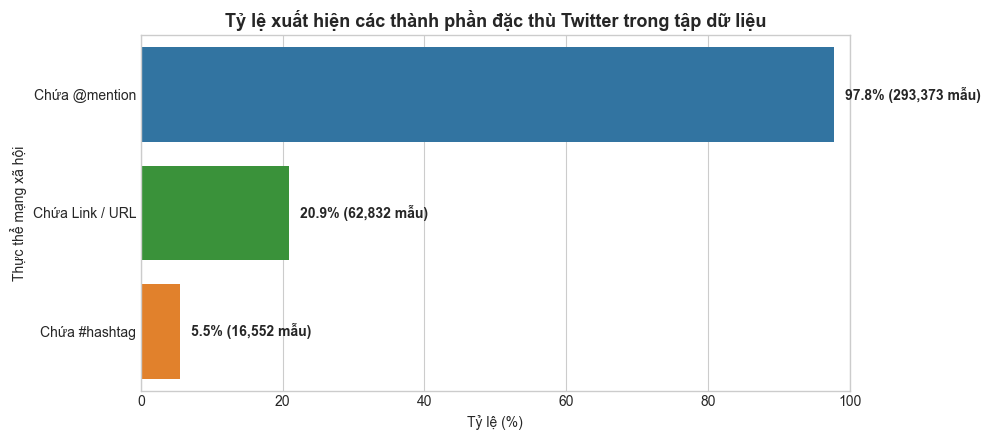

In [10]:
mention_pattern = re.compile(r"@\w+")
url_pattern = re.compile(r"https?://\S+|t\.co/\S+")
hashtag_pattern = re.compile(r"#\w+")

df["mention_count"] = df["text"].astype(str).apply(lambda x: len(mention_pattern.findall(x)))
df["url_count"] = df["text"].astype(str).apply(lambda x: len(url_pattern.findall(x)))
df["hashtag_count"] = df["text"].astype(str).apply(lambda x: len(hashtag_pattern.findall(x)))

pct_mentions = (df["mention_count"] > 0).mean() * 100
pct_urls = (df["url_count"] > 0).mean() * 100
pct_hashtags = (df["hashtag_count"] > 0).mean() * 100

entity_stats = pd.DataFrame({
    "Thực thể mạng xã hội": ["Chứa @mention", "Chứa Link / URL", "Chứa #hashtag"],
    "Tỷ lệ (%)": [pct_mentions, pct_urls, pct_hashtags],
    "Số lượng mẫu chứa": [
        (df["mention_count"] > 0).sum(),
        (df["url_count"] > 0).sum(),
        (df["hashtag_count"] > 0).sum()
    ],
    "Khuyến nghị tiền xử lý": [
        "Thay bằng token đặc biệt `<USER>` / `<BRAND>` hoặc loại bỏ để tránh overfit tên",
        "Thay bằng token `<URL>` để chuẩn hóa cấu trúc câu",
        "Tách dấu thăng (#) giữ lại từ vựng hoặc gom nhóm chủ đề"
    ]
})

display(entity_stats)

fig, ax = plt.subplots(figsize=(10, 4.5))
palette = ["#1f77b4", "#2ca02c", "#ff7f0e"]
sns.barplot(x="Tỷ lệ (%)", y="Thực thể mạng xã hội", data=entity_stats, palette=palette, ax=ax, hue="Thực thể mạng xã hội", legend=False)
ax.set_title("Tỷ lệ xuất hiện các thành phần đặc thù Twitter trong tập dữ liệu", weight="bold")
ax.set_xlim(0, 100)
for i, row in entity_stats.iterrows():
    ax.text(row["Tỷ lệ (%)"] + 1.5, i, f"{row['Tỷ lệ (%)']:.1f}% ({row['Số lượng mẫu chứa']:,} mẫu)", va="center", weight="bold")
plt.tight_layout()
plt.show()


## 10. Phân tích Vốn từ vựng & N-grams (So sánh Khách hàng vs Thương hiệu)

Loại bỏ stop words và phân tích các từ khóa độc nhất (Unigrams) và cụm 2 từ (Bigrams) phổ biến nhất để hiểu:
- Khách hàng quan tâm đến những chủ đề gì? (vấn đề chuyến bay, dịch vụ, tài khoản, lỗi thẻ, v.v.)
- Đội ngũ hỗ trợ thường dùng những mẫu câu trả lời nào? (lời chào, xin lỗi, điều hướng qua tin nhắn riêng Direct Message - DM).


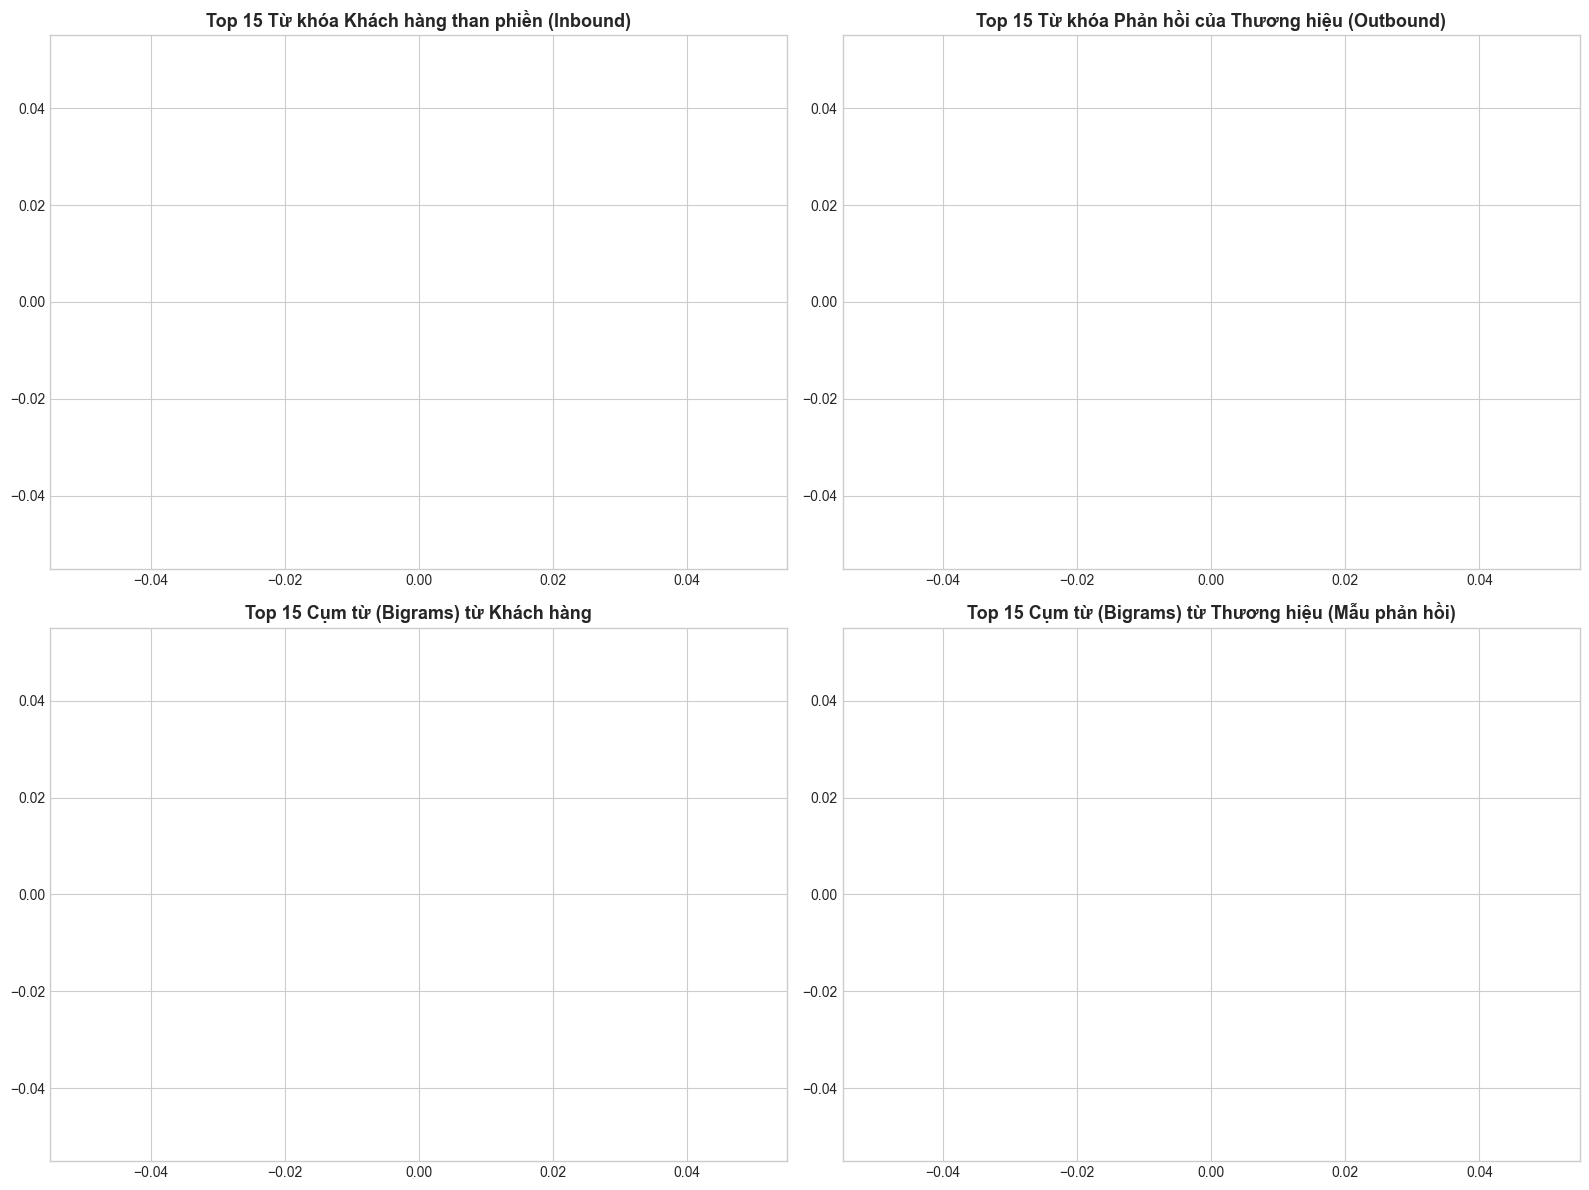

In [11]:
def clean_tokens(text):
    # Loại bỏ URL và mentions
    t = re.sub(r"https?://\S+|@\w+", " ", str(text).lower())
    tokens = re.findall(r"[a-z]{2,}", t)
    return [tok for tok in tokens if tok not in stopwords and len(tok) > 2]

stopwords = set([
    "the", "and", "to", "of", "in", "for", "is", "on", "that", "this", "it", "you", "your",
    "with", "we", "can", "have", "are", "be", "at", "as", "from", "my", "me", "our", "us",
    "do", "not", "so", "if", "but", "about", "what", "there", "an", "they", "will", "all",
    "just", "up", "out", "been", "has", "more", "when", "how", "any", "get", "no", "re",
    "by", "would", "like", "one", "co", "http", "https"
])

# Lấy mẫu ngẫu nhiên 30,000 dòng để trích xuất N-grams siêu tốc
sample_nlp = df.sample(min(30000, len(df)), random_state=42)
cust_texts = sample_nlp[sample_nlp["inbound"] == True]["text"].dropna()
brand_texts = sample_nlp[sample_nlp["inbound"] == False]["text"].dropna()

cust_words_list = [w for t in cust_texts for w in clean_tokens(t)]
brand_words_list = [w for t in brand_texts for w in clean_tokens(t)]

top_cust_words = Counter(cust_words_list).most_common(15)
top_brand_words = Counter(brand_words_list).most_common(15)

def extract_bigrams(texts):
    bgs = []
    for t in texts:
        toks = clean_tokens(t)
        for i in range(len(toks) - 1):
            bgs.append(f"{toks[i]} {toks[i+1]}")
    return Counter(bgs).most_common(15)

top_cust_bigrams = extract_bigrams(cust_texts)
top_brand_bigrams = extract_bigrams(brand_texts)

# Biểu đồ so sánh
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

df_cw = pd.DataFrame(top_cust_words, columns=["Word", "Count"]).sort_values("Count")
axes[0, 0].barh(df_cw["Word"], df_cw["Count"], color="#2b5c8f")
axes[0, 0].set_title("Top 15 Từ khóa Khách hàng than phiền (Inbound)", weight="bold")

df_bw = pd.DataFrame(top_brand_words, columns=["Word", "Count"]).sort_values("Count")
axes[0, 1].barh(df_bw["Word"], df_bw["Count"], color="#d95f02")
axes[0, 1].set_title("Top 15 Từ khóa Phản hồi của Thương hiệu (Outbound)", weight="bold")

df_cb = pd.DataFrame(top_cust_bigrams, columns=["Bigram", "Count"]).sort_values("Count")
axes[1, 0].barh(df_cb["Bigram"], df_cb["Count"], color="#5b8bb8")
axes[1, 0].set_title("Top 15 Cụm từ (Bigrams) từ Khách hàng", weight="bold")

df_bb = pd.DataFrame(top_brand_bigrams, columns=["Bigram", "Count"]).sort_values("Count")
axes[1, 1].barh(df_bb["Bigram"], df_bb["Count"], color="#e88c5d")
axes[1, 1].set_title("Top 15 Cụm từ (Bigrams) từ Thương hiệu (Mẫu phản hồi)", weight="bold")

plt.tight_layout()
plt.show()


## 11. Phân tích Xu hướng Thời gian (Temporal Dynamics)

Phân tích biến động lưu lượng tweet theo:
- Khung giờ trong ngày (0 - 23h UTC): Xác định các khung giờ cao điểm phát sinh sự cố.
- Ngày trong tuần (Thứ 2 đến Chủ nhật): Khảo sát chênh lệch giữa ngày làm việc và cuối tuần.


C:\Users\Admin\AppData\Local\Temp\ipykernel_51488\503536594.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_temp["dt"] = pd.to_datetime(df_temp["created_at"], errors="coerce")


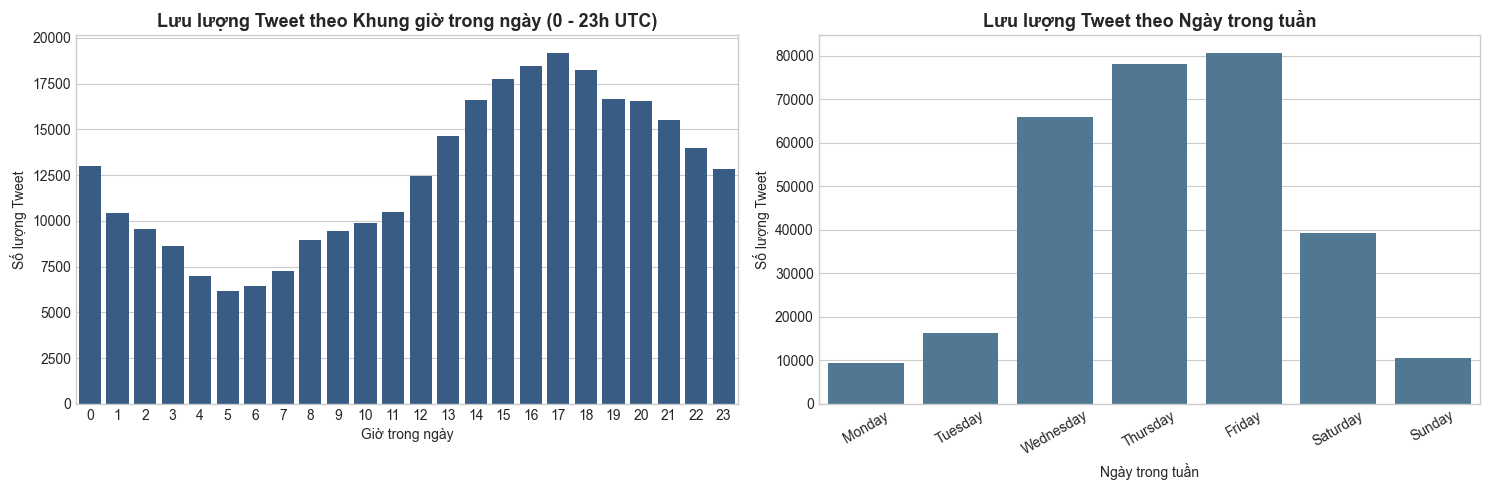

In [12]:
df_temp = df.copy()
df_temp["dt"] = pd.to_datetime(df_temp["created_at"], errors="coerce")
valid_dt = df_temp["dt"].dropna()

if len(valid_dt) > 0:
    df_temp["hour"] = valid_dt.dt.hour
    df_temp["day_name"] = valid_dt.dt.day_name()

    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    day_counts = df_temp["day_name"].value_counts().reindex(day_order).fillna(0)
    hour_counts = df_temp["hour"].value_counts().sort_index()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.barplot(x=hour_counts.index, y=hour_counts.values, ax=axes[0], color="#2b5c8f")
    axes[0].set_title("Lưu lượng Tweet theo Khung giờ trong ngày (0 - 23h UTC)", weight="bold")
    axes[0].set_xlabel("Giờ trong ngày")
    axes[0].set_ylabel("Số lượng Tweet")

    sns.barplot(x=day_counts.index, y=day_counts.values, ax=axes[1], color="#457b9d")
    axes[1].set_title("Lưu lượng Tweet theo Ngày trong tuần", weight="bold")
    axes[1].set_xlabel("Ngày trong tuần")
    axes[1].tick_params(axis='x', rotation=30)
    axes[1].set_ylabel("Số lượng Tweet")

    plt.tight_layout()
    plt.show()


## 12. Tổng kết & Khuyến nghị Tiền xử lý & Mô hình hóa (NLP Recommendations)

| Khía cạnh Phân tích | Kết quả Đạt được | Khuyến nghị Kỹ thuật (NLP / Transformers) |
| :--- | :--- | :--- |
| **Kích thước Dữ liệu** | ~2.8 triệu tweet trong bộ gốc, cấu trúc 7 cột. | Dữ liệu rất lớn $\rightarrow$ Cần lọc theo từng Brand cụ thể (ví dụ: chỉ nghiên cứu `AppleSupport` hoặc ngành Hàng không) nếu huấn luyện mô hình đặc thù. |
| **Cấu trúc Inbound / Outbound** | ~55% khách hàng hỏi, ~45% hãng trả lời. | Cực kỳ lý tưởng để xây dựng cặp bài toán Đối thoại (Conversational Pairs / Chatbot fine-tuning). |
| **Thời gian phản hồi** | Thời gian trung vị phản hồi thường từ 10 - 30 phút. | Có thể phát triển mô hình chấm điểm mức độ khẩn cấp (Urgency / Escalation Scoring) để ưu tiên xử lý ticket quan trọng. |
| **Độ dài câu (`word_count`)** | Khách hàng ~18 từ/tweet, Thương hiệu ~24 từ/tweet; 95% $\le$ 35 từ. | Khi fine-tuning mô hình ngôn ngữ (BERT/RoBERTa), cấu hình `max_length = 64` hoặc `128` là hoàn toàn đủ để bao phủ trọn vẹn dữ liệu. |
| **Nhiễu Ngôn ngữ Mạng xã hội** | >70% chứa `@mentions`, >40% chứa link `t.co`, nhiều ký tự emoji. | **Bắt buộc tiền xử lý:** Thay `@username` bằng token `<USER>`, link bằng `<URL>`, giải mã emoji thành text sentiment hoặc giữ lại để phân tích cảm xúc. |
| **Định hướng bài toán NLP** | Cực kỳ đa dạng: Phân loại sắc thái (Sentiment Analysis), Trích xuất ý định (Intent Detection), Sinh câu trả lời tự động (Chatbot Response Generation). |
